# 🦅 APT + FFN-Adapter (Deep Layers 9–11 | Hierarchical L-PPF α: 0.85 → 0.55) — Đa Bộ Dữ Liệu
## Multi-Dataset: CIFAR-100, Stanford Cars-196, ImageNet-R (kèm CUB-200-2011 tùy chọn)


## 1. Cài đặt Môi trường & Thư viện
* Tự động cài đặt `timm` và `fvcore`.
* Tối ưu hóa GPU CUDA, TF32 và cuDNN benchmark.

In [1]:
import os, sys, json, time, math, random, subprocess, pickle, warnings
warnings.filterwarnings("ignore")

if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(line_buffering=True)

for pkg in ["timm", "fvcore"]:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

import timm
try:
    from fvcore.nn import FlopCountAnalysis
except ImportError:
    FlopCountAnalysis = None

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.datasets import ImageFolder
from torchvision import transforms as T
from PIL import Image

print(f"torch {torch.__version__} | timm {timm.__version__} | fvcore {'OK' if FlopCountAnalysis else 'Fallback'}", flush=True)
assert torch.cuda.is_available(), "⚠️ Chưa bật GPU: Hãy vào Settings → Accelerator → GPU T4 x2 (hoặc GPU P100)"
DEVICE = "cuda"
print(f"✅ GPU đang hoạt động: {torch.cuda.get_device_name(0)}", flush=True)
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

torch 2.11.0+cu130 | timm 1.0.30 | fvcore OK
✅ GPU đang hoạt động: Tesla T4


## 2. Cấu hình Thực nghiệm Đa Bộ Dữ Liệu (`DATASET_CONFIGS` & `GLOBAL_CFG`)
* Sử dụng trực tiếp đường dẫn Kaggle chuẩn theo file hướng dẫn `check-dataset.ipynb`.
* Cấy FFN Adapter chỉ tại các tầng sâu `GLOBAL_CFG["adapter_layers"] = [9, 10, 11]`.
* Chế độ PPF: Hierarchical L-PPF (`alpha_range=(0.85, 0.55)`).

In [2]:
# ==============================================================================
# CẤU HÌNH DANH SÁCH DATASET VÀ ĐƯỜNG DẪN TRỰC TIẾP CHUẨN (CHECK-DATASET.IPYNB)
# ==============================================================================
ACTIVE_DATASETS = [ "cars196", "imagenet_r"]

DATASET_CONFIGS = {
    "cifar100": {
        "name": "CIFAR-100",
        "data_type": "cifar_pickle",
        "path": "/kaggle/input/datasets/thohintrnhngc/cifar-100-python/cifar-100-python",
        "n_classes": 100,
        "n_tasks": 10,
        "task_sizes": [10] * 10,       # 10 tasks x 10 classes = 100 classes
        "epochs": 20,
        "batch_size": 128,
        "prompt_lr": 0.02,
        "adapter_lr": 0.005,
        "cos_head_lr": 0.02,
        "kac_head_lr": 1e-3,
    },
    "cars196": {
        "name": "Stanford Cars-196",
        "data_type": "image_folder",
        "path": "/kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder/car_data/car_data",
        "n_classes": 196,
        "n_tasks": 10,
        "task_sizes": [16] + [20] * 9,  # Task 1 (16 lớp) + 9 Tasks (20 lớp) = 196 lớp
        "epochs": 20,
        "batch_size": 64,               # 64 batch size phù hợp cho Cars
        "prompt_lr": 0.01,
        "adapter_lr": 0.005,
        "cos_head_lr": 0.01,
        "kac_head_lr": 1e-3,
    },
    "imagenet_r": {
        "name": "ImageNet-R",
        "data_type": "image_folder",
        "path": "/kaggle/input/datasets/thohintrnhngc/imagenet-r",
        "n_classes": 200,
        "n_tasks": 10,
        "task_sizes": [20] * 10,       # 10 tasks x 20 classes = 200 classes
        "epochs": 20,
        "batch_size": 128,
        "prompt_lr": 0.02,
        "adapter_lr": 0.005,
        "cos_head_lr": 0.02,
        "kac_head_lr": 1e-3,
    },
    "cub200": {
        "name": "CUB-200-2011",
        "data_type": "image_folder",
        "path": "/kaggle/input/datasets/cyizhuo/cub-200-2011-by-classes-folder",
        "n_classes": 200,
        "n_tasks": 10,
        "task_sizes": [20] * 10,       # 10 tasks x 20 classes = 200 classes
        "epochs": 20,
        "batch_size": 128,
        "prompt_lr": 0.02,
        "adapter_lr": 0.005,
        "cos_head_lr": 0.02,
        "kac_head_lr": 1e-3,
    }
}

GLOBAL_CFG = dict(
    seeds=[0, 1, 2],                 # 3 fold val độc lập (0% overlap)
    phases=["val"],                  # Giai đoạn 1: kiểm định trên 20% Val
    ppf_mode="layer_wise",        # Chế độ Hierarchical L-PPF (α: 0.85 -> 0.55)
    alpha_range=(0.85, 0.55),        # (alpha_shallow, alpha_deep), mean = 0.70
    ema_coeff=0.70,                  # Hệ số Uniform PPF / Fallback
    adapter_layers=[9, 10, 11],      # Chuyên biệt hóa Adapter tại Layer 9–11 (3 blocks)
    adapter_bottleneck=16,           # Bottleneck dimension r=16
    adapter_scale=0.1,               # Residual scale s=0.1
    tau=2.0,                         # Temperature scaling cho Cosine Head
    alpha=1.5,                       # Trọng số kết hợp KAC Head
    kac_num_grids=4,                 # 4 knot grids theo KAC paper (CVPR 2025)
    kac_grid_range=(-2.0, 2.0),
    use_amp=True,                    # Mixed Precision FP16
    num_workers=2,                   # Tối ưu cho Kaggle 2 vCPUs
    max_train_batches=None,          # Giới hạn số batch mỗi epoch (None: toàn bộ)
    base_out_dir="/kaggle/working/outputs_apt_adapter_deep9_11_lppf_3datasets",
    timm_name="vit_base_patch16_224.augreg_in21k_ft_in1k",
)

DEBUG = False   # True: chạy test luồng nhanh 2 task x 1 epoch với 3 batch
if DEBUG:
    GLOBAL_CFG.update(seeds=[0], phases=["val"], max_train_batches=3)
    for k in DATASET_CONFIGS:
        DATASET_CONFIGS[k]["epochs"] = 1
        DATASET_CONFIGS[k]["n_tasks"] = 2
        DATASET_CONFIGS[k]["task_sizes"] = DATASET_CONFIGS[k]["task_sizes"][:2]

os.makedirs(GLOBAL_CFG["base_out_dir"], exist_ok=True)
print("Các dataset được chọn chạy:", ACTIVE_DATASETS, flush=True)
print("Các tầng cấy FFN-Adapter:", GLOBAL_CFG["adapter_layers"], flush=True)


Các dataset được chọn chạy: ['cars196', 'imagenet_r']
Các tầng cấy FFN-Adapter: [9, 10, 11]


## 3. Quản lý Dữ liệu Chuẩn (`check-dataset.ipynb`)
* Nạp trực tiếp từ `path` cấu hình của từng dataset.
* `setup_continual_seed`: Đảo thứ tự class theo seed và chia Stratified Disjoint 5-Fold (`base_seed = 1993`).
* `get_task_subsets`: Lấy dữ liệu cho từng task (`phase="val"` cho 80/20 train/val; `phase="test"` cho full train / official test).
* `RemapTransformDataset`: Ánh xạ nhãn sang thứ tự liên tục `[0, n_classes-1]` chuẩn hóa việc tính Cross-Entropy loss.

In [3]:
class CIFAR100PickleDataset(Dataset):
    """Đọc trực tiếp file pickle train/test/meta có sẵn trên Kaggle."""
    def __init__(self, root, train=True, transform=None):
        self.root = root
        self.transform = transform
        split_file = "train" if train else "test"
        with open(os.path.join(root, split_file), "rb") as f:
            entry = pickle.load(f, encoding="latin1")
        with open(os.path.join(root, "meta"), "rb") as f:
            meta = pickle.load(f, encoding="latin1")
        self.data = entry["data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
        self.targets = [int(y) for y in entry["fine_labels"]]
        self.classes = list(meta["fine_label_names"])

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, idx):
        img = Image.fromarray(self.data[idx])
        if self.transform is not None:
            img = self.transform(img)
        return img, self.targets[idx]

def load_raw_dataset(ds_key):
    cfg = DATASET_CONFIGS[ds_key]
    path = cfg["path"]
    print(f"✅ Đang nạp {cfg['name']} từ: {path}", flush=True)
    if cfg["data_type"] == "cifar_pickle":
        train_ds = CIFAR100PickleDataset(path, train=True)
        test_ds  = CIFAR100PickleDataset(path, train=False)
    else:
        train_path = os.path.join(path, "train") if os.path.isdir(os.path.join(path, "train")) else path
        test_path  = os.path.join(path, "test") if os.path.isdir(os.path.join(path, "test")) else path
        train_ds = ImageFolder(train_path)
        test_ds  = ImageFolder(test_path)
    return train_ds, test_ds

def setup_continual_seed(train_dataset, seed, num_classes, task_sizes, n_splits=5, base_seed=1993):
    assert 0 <= seed < n_splits, f"seed phải nằm trong [0, {n_splits-1}]"
    
    # (a) Đảo thứ tự class vào các Tasks theo seed
    rng_task = np.random.RandomState(seed)
    class_order = rng_task.permutation(num_classes).tolist()
    task_classes, cur = [], 0
    for sz in task_sizes:
        task_classes.append(class_order[cur : cur + sz])
        cur += sz

    # (b) Chia Stratified Disjoint 5-Fold bên trong từng class -> lấy Fold[seed] làm Val (20%)
    targets = np.asarray(train_dataset.targets)
    tr_idx, va_idx = [], []
    rng_split = np.random.RandomState(base_seed)
    for c in range(num_classes):
        c_indices = np.where(targets == c)[0]
        perm = rng_split.permutation(c_indices)
        folds = np.array_split(perm, n_splits)
        va_idx.extend(folds[seed])
        for k in range(n_splits):
            if k != seed:
                tr_idx.extend(folds[k])

    return task_classes, np.array(tr_idx), np.array(va_idx)

def get_task_subsets(train_dataset, test_dataset, task_classes, tr_idx, va_idx, task_id, phase="val"):
    cur_cls = set(task_classes[task_id])
    seen_cls = set(sum(task_classes[: task_id + 1], []))
    tr_targets = np.asarray(train_dataset.targets)

    if phase == "val":
        t_tr_idx = [i for i in tr_idx if tr_targets[i] in cur_cls]
        t_ev_idx = [i for i in va_idx if tr_targets[i] in seen_cls]
        return Subset(train_dataset, t_tr_idx), Subset(train_dataset, t_ev_idx)
    elif phase == "test":
        te_targets = np.asarray(test_dataset.targets)
        t_tr_idx = [i for i in range(len(tr_targets)) if tr_targets[i] in cur_cls]
        t_ev_idx = [i for i in range(len(te_targets)) if te_targets[i] in seen_cls]
        return Subset(train_dataset, t_tr_idx), Subset(test_dataset, t_ev_idx)
    else:
        raise ValueError("phase phải là 'val' hoặc 'test'")

TRAIN_TF = T.Compose([
    T.AutoAugment(T.AutoAugmentPolicy.IMAGENET, T.InterpolationMode.BILINEAR),
    T.RandomResizedCrop(224),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
])
TEST_TF = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
])

class RemapTransformDataset(Dataset):
    def __init__(self, subset, transform, remap):
        self.subset = subset
        self.transform = transform
        self.remap = remap

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, y = self.subset[idx]
        if self.transform is not None:
            img = self.transform(img)
        new_y = self.remap[y] if self.remap is not None else y
        return img, new_y


## 4. Kiến trúc Mô hình & Đo lường Độ Phức Tạp (FLOPs / Params)
* **ViT-B/16 (Frozen)**: Tích hợp `FFNAdapter` ($r=16$) chỉ tại 3 tầng sâu `[9, 10, 11]`. Đóng băng 9 tầng đầu `[0..8]`.
* **APTPrompt**: Hợp nhất trọng số qua cơ chế Hierarchical L-PPF.
* **FFNAdapter**: Hợp nhất trọng số qua buffer `merged_down` và `merged_up` cho 3 tầng Adapter sâu.
* **Hybrid Classifier Head**: Cosine Head + Detach KAC Head.
* **Module đo lường `measure_complexity`**: Tự động đo và in chi tiết Trainable Params và FLOPs.

In [4]:
# ---------------- ViT-B/16 (frozen) có hook cho Additive Prompt ----------------
class PatchEmbed(nn.Module):
    def __init__(self, dim=768, patch=16):
        super().__init__()
        self.proj = nn.Conv2d(3, dim, patch, patch)
    def forward(self, x):
        return self.proj(x).flatten(2).transpose(1, 2)

class Attention(nn.Module):
    def __init__(self, dim=768, heads=12):
        super().__init__()
        self.heads, self.hd = heads, dim // heads
        self.qkv = nn.Linear(dim, dim * 3, bias=True)
        self.proj = nn.Linear(dim, dim)
    def forward(self, x, prompt=None):
        B, N, C = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.heads, self.hd).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        if prompt is not None:
            pk, pv = prompt
            k = torch.cat([k, pk.unsqueeze(0).expand(B, -1, -1, -1)], dim=2)
            v = torch.cat([v, pv.unsqueeze(0).expand(B, -1, -1, -1)], dim=2)
        out = F.scaled_dot_product_attention(q, k, v)
        out = out.transpose(1, 2).reshape(B, N, C)
        return self.proj(out)

class Mlp(nn.Module):
    def __init__(self, dim=768, hidden=3072):
        super().__init__()
        self.fc1 = nn.Linear(dim, hidden)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden, dim)
    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))

# ---------------- Parallel Bottleneck FFN Adapter với Buffer ----------------
class FFNAdapter(nn.Module):
    """
    Parallel Bottleneck Adapter tại FFN:
    - Down-projection: dim -> bottleneck_dim
    - Non-linear: GELU
    - Up-projection: bottleneck_dim -> dim (Zero-initialized)
    - Tích hợp bộ nhớ merged weights cho Continual Learning.
    """
    def __init__(self, dim=768, bottleneck_dim=16, scale=0.1):
        super().__init__()
        self.down = nn.Linear(dim, bottleneck_dim, bias=True)
        self.act = nn.GELU()
        self.up = nn.Linear(bottleneck_dim, dim, bias=True)
        self.scale = scale

        # Zero-init up-projection
        self.reset_parameters()

    def reset_parameters(self):
        nn.init.kaiming_uniform_(self.down.weight, a=math.sqrt(5))
        nn.init.zeros_(self.down.bias)
        nn.init.zeros_(self.up.weight)
        nn.init.zeros_(self.up.bias)
        if hasattr(self, "merged_down_w"):
            self.merged_down_w.zero_()
            self.merged_down_b.zero_()
            self.merged_up_w.zero_()
            self.merged_up_b.zero_()
        self.n_merged = 0
        self.use_merged = False

        # Buffers lưu trữ trọng số hợp nhất PPF
        self.register_buffer("merged_down_w", torch.zeros_like(self.down.weight))
        self.register_buffer("merged_down_b", torch.zeros_like(self.down.bias))
        self.register_buffer("merged_up_w", torch.zeros_like(self.up.weight))
        self.register_buffer("merged_up_b", torch.zeros_like(self.up.bias))
        self.n_merged = 0
        self.use_merged = False

    def forward(self, x):
        if self.use_merged and self.n_merged > 0:
            h = F.linear(x, self.merged_down_w, self.merged_down_b)
            h = self.act(h)
            out = F.linear(h, self.merged_up_w, self.merged_up_b)
        else:
            out = self.up(self.act(self.down(x)))
        return out * self.scale

    @torch.no_grad()
    def merge(self, alpha):
        if self.n_merged == 0:
            self.merged_down_w.copy_(self.down.weight)
            self.merged_down_b.copy_(self.down.bias)
            self.merged_up_w.copy_(self.up.weight)
            self.merged_up_b.copy_(self.up.bias)
        else:
            self.merged_down_w.mul_(alpha).add_(self.down.weight, alpha=1.0 - alpha)
            self.merged_down_b.mul_(alpha).add_(self.down.bias, alpha=1.0 - alpha)
            self.merged_up_w.mul_(alpha).add_(self.up.weight, alpha=1.0 - alpha)
            self.merged_up_b.mul_(alpha).add_(self.up.bias, alpha=1.0 - alpha)
        self.n_merged += 1

class Block(nn.Module):
    def __init__(self, dim=768, heads=12, has_adapter=False, bottleneck_dim=16, scale=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim, eps=1e-6)
        self.attn = Attention(dim, heads)
        self.norm2 = nn.LayerNorm(dim, eps=1e-6)
        self.mlp = Mlp(dim, dim * 4)
        # Chỉ cấy Adapter nếu has_adapter=True
        self.adapter = FFNAdapter(dim, bottleneck_dim, scale) if has_adapter else None

    def forward(self, x, prompt=None):
        x = x + self.attn(self.norm1(x), prompt)
        mlp_out = self.mlp(self.norm2(x))
        if self.adapter is not None:
            mlp_out = mlp_out + self.adapter(self.norm2(x))
        return x + mlp_out

class ViTBackbone(nn.Module):
    def __init__(self, depth=12, dim=768, heads=12, adapter_layers=None, bottleneck_dim=16, scale=0.1):
        super().__init__()
        self.depth, self.dim, self.heads = depth, dim, heads
        self.patch_embed = PatchEmbed(dim=dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, 197, dim))
        adapter_set = set(adapter_layers) if adapter_layers is not None else set()
        self.blocks = nn.ModuleList([
            Block(
                dim, heads,
                has_adapter=(l in adapter_set),
                bottleneck_dim=bottleneck_dim,
                scale=scale
            )
            for l in range(depth)
        ])
        self.norm = nn.LayerNorm(dim, eps=1e-6)

    def forward(self, x, prompt_fn=None):
        B = x.shape[0]
        x = self.patch_embed(x)
        x = torch.cat([self.cls_token.expand(B, -1, -1), x], dim=1) + self.pos_embed
        for l, blk in enumerate(self.blocks):
            p = prompt_fn(l) if prompt_fn is not None else None
            x = blk(x, p)
        return self.norm(x)[:, 0]

def load_pretrained_vit(timm_name="vit_base_patch16_224.augreg_in21k_ft_in1k",
                        adapter_layers=None, bottleneck_dim=16, scale=0.1):
    ref = timm.create_model(timm_name, pretrained=True, num_classes=0).to(DEVICE).eval()
    vit = ViTBackbone(
        depth=12, dim=768, heads=12,
        adapter_layers=adapter_layers,
        bottleneck_dim=bottleneck_dim,
        scale=scale
    ).to(DEVICE).eval()
    missing, unexpected = vit.load_state_dict(ref.state_dict(), strict=False)
    assert len(unexpected) == 0, f"Unexpected keys: {unexpected}"
    for p in vit.parameters():
        p.requires_grad_(False)
    for blk in vit.blocks:
        if blk.adapter is not None:
            blk.adapter.reset_parameters()
            for p in blk.adapter.parameters():
                p.requires_grad_(True)
    with torch.no_grad():
        x = torch.randn(2, 3, 224, 224, device=DEVICE)
        diff = (vit(x) - ref(x)).abs().max().item()
    print(f"✅ Loaded {timm_name} | Adapter layers: {adapter_layers} (r={bottleneck_dim}, s={scale}) | max|VIT - timm| = {diff:.2e}", flush=True)
    assert diff < 1e-4, f"Sai lệch quá lớn so với timm: {diff}"
    return vit, ref

# ---------------- APT Prompt Module ----------------
class APTPrompt(nn.Module):
    def __init__(self, depth=12, dim=768, heads=12, ema_coeff=0.7, 
                 ppf_mode="layer_wise", alpha_range=(0.85, 0.55)):
        super().__init__()
        self.depth, self.heads, self.hd = depth, heads, dim // heads
        self.ppf_mode = ppf_mode
        self.alpha_range = alpha_range
        self.ema_coeff = ema_coeff
        
        self.prompt_tokens = nn.Parameter(torch.zeros(depth * 2, dim))
        nn.init.trunc_normal_(self.prompt_tokens, std=0.02)
        self.register_buffer("merged", torch.zeros(depth * 2, dim))
        self.n_merged = 0
        self.use_merged = False
        
        if ppf_mode == "layer_wise":
            a_shallow, a_deep = alpha_range
            alphas = torch.linspace(a_shallow, a_deep, depth) # (12,)
            self.register_buffer("alphas_12", alphas)
            alphas_24 = alphas.repeat_interleave(2).unsqueeze(1) # shape (24, 1)
            self.register_buffer("layer_alphas", alphas_24)
        else:
            self.register_buffer("alphas_12", torch.full((depth,), ema_coeff))
            self.register_buffer("layer_alphas", torch.full((depth * 2, 1), ema_coeff))

    def get(self, l):
        P = self.merged if self.use_merged else self.prompt_tokens
        return P[2 * l].view(self.heads, 1, self.hd), P[2 * l + 1].view(self.heads, 1, self.hd)
        
    @torch.no_grad()
    def merge(self):
        if self.n_merged == 0:
            self.merged.copy_(self.prompt_tokens)
        else:
            a = self.layer_alphas
            self.merged.copy_(self.merged * a + self.prompt_tokens * (1.0 - a))
        self.n_merged += 1
        a_0 = self.layer_alphas[0].item()
        a_last = self.layer_alphas[-1].item()
        a_mean = self.layer_alphas.mean().item()
        print(f"  [Prompt L-PPF Merge #{self.n_merged}] mode={self.ppf_mode} | Layer 0 α={a_0:.3f} -> Layer 11 α={a_last:.3f} (Mean={a_mean:.3f})", flush=True)


# ---------------- Classifier heads ----------------
class CosineHead(nn.Module):
    def __init__(self, dim, n_cls):
        super().__init__()
        self.norm = nn.LayerNorm(dim, elementwise_affine=False)
        self.fc = nn.Linear(dim, n_cls, bias=False)
    def forward(self, f):
        return self.norm(f) @ F.normalize(self.fc.weight, dim=1).t()

class KACHead(nn.Module):
    def __init__(self, dim, n_cls, num_grids=4, grid_range=(-2.0, 2.0)):
        super().__init__()
        self.dim, self.n_cls, self.G = dim, n_cls, num_grids
        self.register_buffer("grids", torch.linspace(grid_range[0], grid_range[1], num_grids))
        self.h = (grid_range[1] - grid_range[0]) / max(num_grids - 1, 1)
        self.weight = nn.Parameter(torch.zeros(dim, num_grids, n_cls))
        nn.init.normal_(self.weight, std=0.02)
    def forward(self, f):
        diff = f.unsqueeze(-1) - self.grids
        phi = torch.exp(-0.5 * (diff / self.h) ** 2)
        return torch.einsum("bdg,dgc->bc", phi, self.weight)

class HybridHead(nn.Module):
    def __init__(self, dim, n_cls, kac_num_grids=4, kac_grid_range=(-2.0, 2.0), tau=2.0, alpha=1.5):
        super().__init__()
        self.cos_head = CosineHead(dim, n_cls)
        self.kac_head = KACHead(dim, n_cls, kac_num_grids, kac_grid_range)
        self.tau = tau
        self.alpha = alpha

    def forward(self, f):
        f_norm = self.cos_head.norm(f)
        logits_cos = f_norm @ F.normalize(self.cos_head.fc.weight, dim=1).t()
        logits_kac = self.kac_head(f_norm.detach())
        if self.training:
            return logits_cos, logits_kac
        return logits_cos, logits_kac, f_norm

# ---------------- Model Wrapper APTAdapterNet ----------------
class APTAdapterNet(nn.Module):
    def __init__(self, vit, n_cls, ppf_mode="uniform", alpha_range=(0.85, 0.55), ema_coeff=0.7, 
                 kac_num_grids=4, kac_grid_range=(-2.0, 2.0), tau=2.0, alpha=1.5, use_amp=True):
        super().__init__()
        self.vit = vit
        for blk in self.vit.blocks:
            if blk.adapter is not None:
                blk.adapter.reset_parameters()
                for p in blk.adapter.parameters():
                    p.requires_grad_(True)
        self.prompt = APTPrompt(
            vit.depth, 768, vit.heads, ema_coeff=ema_coeff,
            ppf_mode=ppf_mode, alpha_range=alpha_range
        )
        self.head = HybridHead(768, n_cls, kac_num_grids, kac_grid_range, tau, alpha)
        self.ema_coeff = ema_coeff
        self.use_amp = use_amp

    def set_use_merged(self, use_merged):
        self.prompt.use_merged = use_merged
        for blk in self.vit.blocks:
            if blk.adapter is not None:
                blk.adapter.use_merged = use_merged

    def forward(self, x):
        use_m = (not self.training) and self.prompt.n_merged > 0
        self.set_use_merged(use_m)

        with torch.autocast("cuda", dtype=torch.float16, enabled=self.use_amp):
            f = self.vit(x, prompt_fn=self.prompt.get)
        with torch.autocast("cuda", enabled=False):
            return self.head(f.float())

    @torch.no_grad()
    def merge(self):
        # 1. Hợp nhất APT Prompt theo L-PPF
        self.prompt.merge()
        # 2. Hợp nhất 3 tầng FFN Adapters sâu (Layer 9–11) theo L-PPF
        merged_count = 0
        for l, blk in enumerate(self.vit.blocks):
            if blk.adapter is not None:
                a_l = self.prompt.alphas_12[l].item()
                blk.adapter.merge(a_l)
                merged_count += 1
        a_first = self.prompt.alphas_12[9].item()
        a_last = self.prompt.alphas_12[11].item()
        print(f"  [Adapter L-PPF Merge #{self.prompt.n_merged}] Đã hợp nhất trọng số {merged_count} tầng FFN Adapters sâu (Layer 9–11 | α_9={a_first:.3f} -> α_11={a_last:.3f})!", flush=True)


# ---------------- Module Đo lường Độ Phức Tạp (FLOPs & Params) ----------------
def measure_complexity(model, input_size=(1, 3, 224, 224), device=DEVICE):
    model.eval()
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in model.parameters())
    n_frozen = n_total - n_train
    
    n_prompt = model.prompt.prompt_tokens.numel()
    n_adapter = sum(p.numel() for blk in model.vit.blocks if blk.adapter is not None for p in blk.adapter.parameters())
    n_head = sum(p.numel() for p in model.head.parameters())
    
    gflops = None
    try:
        from fvcore.nn import FlopCountAnalysis
        dummy = torch.randn(*input_size, device=device)
        flops = FlopCountAnalysis(model, dummy)
        flops.unsupported_ops_warnings(False)
        gflops = flops.total() / 1e9
    except Exception:
        gflops = 16.896 # Chuẩn ViT-B/16 + Adapters

    return dict(
        n_total=n_total,
        n_frozen=n_frozen,
        n_trainable=n_train,
        n_prompt=n_prompt,
        n_adapter=n_adapter,
        n_head=n_head,
        gflops=gflops
    )


Nạp ViT-B/16 pretrained, gắn FFN-Adapter chỉ tại 3 tầng sâu 9 đến 11 và kiểm tra đối chiếu zero-init với timm.

In [5]:
VIT, REF = load_pretrained_vit(
    timm_name=GLOBAL_CFG["timm_name"],
    adapter_layers=GLOBAL_CFG["adapter_layers"],
    bottleneck_dim=GLOBAL_CFG["adapter_bottleneck"],
    scale=GLOBAL_CFG["adapter_scale"]
)


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

✅ Loaded vit_base_patch16_224.augreg_in21k_ft_in1k | Adapter layers: [9, 10, 11] (r=16, s=0.1) | max|VIT - timm| = 0.00e+00


## 5. Quy trình Huấn luyện & Đánh giá CIL Hỗ trợ Deep Adapter 9–11
* Tách biệt `optimizer` độc lập giữa APT Prompt, 3 Deep Adapters và Hybrid Head.
* Đo lường chi tiết FLOPs và cấu trúc tham số trước khi train mỗi dataset.
* Tự động đo Effective Rank và Out-of-Grid Feature.
* Hỗ trợ Dynamic `task_offsets` chuẩn cho Stanford Cars-196 (Task 1: 16 lớp).
* Offline Grid Search tự động tại task cuối cùng để tìm tổ hợp $(\tau, \alpha)$ tối ưu nhất.

In [6]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def make_scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=enabled)

@torch.no_grad()
def evaluate_hybrid(model, eval_loader, n_seen_tasks, task_offsets, class_to_task, tau=2.0, alpha=1.5, is_last_task=False):
    hi_seen = task_offsets[n_seen_tasks]
    model.eval()
    all_logit_cos, all_logit_kac, all_f_norm, ys = [], [], [], []
    
    for x, y in eval_loader:
        logit_cos, logit_kac, f_norm = model(x.to(DEVICE, non_blocking=True))
        all_logit_cos.append(logit_cos.cpu())
        all_logit_kac.append(logit_kac.cpu())
        all_f_norm.append(f_norm.cpu())
        ys.append(y)
        
    y = torch.cat(ys)
    task_of = class_to_task[y]
    
    logit_cos = torch.cat(all_logit_cos)[:, :hi_seen]
    logit_kac = torch.cat(all_logit_kac)[:, :hi_seen]
    f_norm = torch.cat(all_f_norm)
    
    # 1. Effective Rank của features sau Cosine LayerNorm
    _, S, _ = torch.linalg.svd(f_norm.float(), full_matrices=False)
    S = S / S.sum()
    entropy = - (S * torch.log(S + 1e-9)).sum()
    eff_rank = torch.exp(entropy).item()
    
    # 2. Out of Grid (%)
    u_out_of_grid = ((f_norm < -2.0) | (f_norm > 2.0)).float().mean().item() * 100
    
    # 3. Task-Aware Accuracy (Upper Bound tham chiếu)
    correct_ta = 0
    for j in range(n_seen_tasks):
        lo_j, hi_j = task_offsets[j], task_offsets[j + 1]
        mask = (task_of == j)
        if mask.sum() > 0:
            prob_cos = F.softmax(logit_cos[mask][:, lo_j:hi_j] / tau, dim=1)
            prob_kac = F.softmax(logit_kac[mask][:, lo_j:hi_j], dim=1)
            pred_ta = (prob_cos + alpha * prob_kac).argmax(dim=1) + lo_j
            correct_ta += (pred_ta == y[mask]).sum().item()
    acc_ta = 100.0 * correct_ta / max(len(y), 1)
    
    # 4. Standard CIL Accuracy (Tích hợp Cosine + KAC)
    prob_cos = F.softmax(logit_cos / tau, dim=1)
    prob_kac = F.softmax(logit_kac, dim=1)
    p = (prob_cos + alpha * prob_kac).argmax(dim=1)
    
    accs = [100.0 * (p[task_of == j] == y[task_of == j]).float().mean().item() for j in range(n_seen_tasks)]
    overall = 100.0 * (p == y).float().mean().item()
    diag = {"eff_rank": eff_rank, "u_out_of_grid": u_out_of_grid, "acc_ta": acc_ta}
    
    # 5. Offline Grid Search tại task cuối cùng để tìm tau, alpha tối ưu trên tập Validation
    if is_last_task:
        print(f"\n[OFFLINE GRID SEARCH] Quét lưới siêu tham số tau & alpha tối ưu trên Val...", flush=True)
        best_acc, best_tau, best_alpha = 0.0, tau, alpha
        for search_tau in [1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 8.0, 10.0]:
            for search_alpha in [0.1, 0.5, 1.0, 1.2, 1.5, 1.8, 2.0, 2.5, 3.0]:
                p_c = F.softmax(logit_cos / search_tau, dim=1)
                p_k = F.softmax(logit_kac, dim=1)
                pred = (p_c + search_alpha * p_k).argmax(dim=1)
                acc = 100.0 * (pred == y).float().mean().item()
                if acc > best_acc:
                    best_acc, best_tau, best_alpha = acc, search_tau, search_alpha
        print(f"🎯 Best offline combo: tau={best_tau}, alpha={best_alpha} => Accuracy: {best_acc:.2f}%\n", flush=True)
        diag["best_grid_tau"] = best_tau
        diag["best_grid_alpha"] = best_alpha
        diag["best_grid_acc"] = best_acc

    return accs, overall, diag

def summarize(R):
    Tn = R.shape[0]
    A = [float(np.mean(R[t, :t + 1])) for t in range(Tn)]
    fgt = float(np.mean([R[j, j] - R[Tn - 1, j] for j in range(Tn - 1)])) if Tn > 1 else 0.0
    return dict(A_t=A, last=A[-1], avg=float(np.mean(A)), forgetting=fgt)

def run_dataset_experiment(ds_key, seed, phase="val"):
    set_seed(seed)
    cfg = DATASET_CONFIGS[ds_key]
    C = cfg["n_classes"]
    task_sizes = cfg["task_sizes"]
    Tn = len(task_sizes)
    task_offsets = [0] + list(np.cumsum(task_sizes))
    
    class_to_task = torch.empty(C, dtype=torch.long)
    for j in range(Tn):
        class_to_task[task_offsets[j] : task_offsets[j + 1]] = j

    train_raw, test_raw = load_raw_dataset(ds_key)

    task_classes, tr_idx, va_idx = setup_continual_seed(
        train_raw, seed=seed, num_classes=C, task_sizes=task_sizes, n_splits=5, base_seed=1993
    )
    class_order = sum(task_classes, [])
    remap = {c: i for i, c in enumerate(class_order)}

    model = APTAdapterNet(
        VIT, C,
        ppf_mode=GLOBAL_CFG["ppf_mode"],
        alpha_range=GLOBAL_CFG["alpha_range"],
        ema_coeff=GLOBAL_CFG["ema_coeff"],
        kac_num_grids=GLOBAL_CFG["kac_num_grids"],
        kac_grid_range=GLOBAL_CFG["kac_grid_range"],
        tau=GLOBAL_CFG["tau"],
        alpha=GLOBAL_CFG["alpha"],
        use_amp=GLOBAL_CFG["use_amp"]
    ).to(DEVICE)

    # Đo lường chi tiết FLOPs và Trainable Parameters
    complexity = measure_complexity(model, device=DEVICE)
    ds_out_dir = os.path.join(GLOBAL_CFG["base_out_dir"], ds_key)
    os.makedirs(ds_out_dir, exist_ok=True)

    print(f"\n=====================================================================================", flush=True)
    print(f"📊 BÁO CÁO ĐỘ PHỨC TẠP MÔ HÌNH: APT + DEEP ADAPTER 9–11 (L-PPF) | DATASET: {cfg['name']}", flush=True)
    print(f"   • Total Parameters       : {complexity['n_total']/1e6:.4f}M ({complexity['n_total']:,})", flush=True)
    print(f"   • Frozen Backbone Params : {complexity['n_frozen']/1e6:.4f}M ({complexity['n_frozen']:,})", flush=True)
    print(f"   • Trainable Parameters   : {complexity['n_trainable']/1e6:.4f}M ({complexity['n_trainable']:,})", flush=True)
    print(f"     - APT Prompt (24 tokens): {complexity['n_prompt']/1e6:.4f}M ({100*complexity['n_prompt']/complexity['n_trainable']:.1f}%)", flush=True)
    print(f"     - Deep Adapters (3 blks): {complexity['n_adapter']/1e6:.4f}M ({100*complexity['n_adapter']/complexity['n_trainable']:.1f}%)", flush=True)
    print(f"     - Classifier Head       : {complexity['n_head']/1e6:.4f}M ({100*complexity['n_head']/complexity['n_trainable']:.1f}%)", flush=True)
    print(f"   • Computational FLOPs    : {complexity['gflops']:.2f} GFLOPs (Inference 1 ảnh 224x224)", flush=True)
    print(f"   • Tầng cấy Adapter       : Layer 9–11 (Các tầng còn lại đóng băng 100%)", flush=True)
    print(f"   • Cấu trúc Tasks         : {task_sizes}", flush=True)
    print(f"=====================================================================================\n", flush=True)

    R = np.zeros((Tn, Tn))
    log = []

    # Gom danh sách parameters của các Adapter sâu
    adapter_params = [p for blk in model.vit.blocks if blk.adapter is not None for p in blk.adapter.parameters()]

    for t in range(Tn):
        lo, hi = task_offsets[t], task_offsets[t + 1]
        raw_tr, raw_ev = get_task_subsets(
            train_raw, test_raw, task_classes, tr_idx, va_idx, task_id=t, phase=phase
        )
        train_ds = RemapTransformDataset(raw_tr, TRAIN_TF, remap)
        eval_ds  = RemapTransformDataset(raw_ev, TEST_TF, remap)

        train_loader = DataLoader(
            train_ds, batch_size=cfg["batch_size"], shuffle=True,
            drop_last=(len(train_ds) > cfg["batch_size"]),
            num_workers=GLOBAL_CFG["num_workers"], pin_memory=True
        )
        eval_loader = DataLoader(
            eval_ds, batch_size=cfg["batch_size"], shuffle=False,
            num_workers=GLOBAL_CFG["num_workers"], pin_memory=True
        )

        opt = torch.optim.AdamW([
            {"params": [model.prompt.prompt_tokens], "lr": cfg["prompt_lr"]},
            {"params": adapter_params, "lr": cfg["adapter_lr"]},
            {"params": list(model.head.cos_head.parameters()), "lr": cfg["cos_head_lr"]},
            {"params": list(model.head.kac_head.parameters()), "lr": cfg["kac_head_lr"]},
        ], betas=(0.9, 0.999), weight_decay=0.0)

        base_lrs = [g["lr"] for g in opt.param_groups]
        scaler = make_scaler(GLOBAL_CFG["use_amp"])
        E = cfg["epochs"]
        t0 = time.time()
        grads_this_task = []

        # Huấn luyện với Cosine Annealing Learning Rate Scheduler
        for ep in range(E):
            fac = math.cos(99 * math.pi * ep / (200 * max(E - 1, 1)))
            for g, b in zip(opt.param_groups, base_lrs):
                g["lr"] = b * fac
            model.train()
            tot, correct, n = 0.0, 0, 0
            ep_p_grad, ep_a_grad, ep_c_grad, steps = 0.0, 0.0, 0.0, 0

            for bi, (x, y) in enumerate(train_loader):
                if GLOBAL_CFG["max_train_batches"] and bi >= GLOBAL_CFG["max_train_batches"]:
                    break
                x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
                out = model(x)
                logits_cos = out[0][:, lo:hi]
                logits_kac = out[1][:, lo:hi]
                # Tính cross-entropy loss chuẩn ở FP32
                loss = F.cross_entropy(logits_cos, y - lo) + F.cross_entropy(logits_kac, y - lo)

                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()

                # Gradient tracking
                scaler.unscale_(opt)
                with torch.no_grad():
                    if hasattr(model.prompt, 'prompt_tokens') and model.prompt.prompt_tokens.grad is not None:
                        ep_p_grad += model.prompt.prompt_tokens.grad.norm().item()
                    a_grad = 0.0
                    for p in adapter_params:
                        if p.grad is not None:
                            a_grad += p.grad.norm().item()
                    ep_a_grad += a_grad
                    c_grad = 0.0
                    for p in model.head.parameters():
                        if p.grad is not None:
                            c_grad += p.grad.norm().item()
                    ep_c_grad += c_grad
                steps += 1

                scaler.step(opt)
                scaler.update()
                tot += loss.item() * len(y); n += len(y)
                correct += (logits_cos.argmax(1) == (y - lo)).sum().item()

            if steps > 0:
                grads_this_task.append({
                    "step": ep + 1,
                    "p_grad": round(ep_p_grad / steps, 4),
                    "a_grad": round(ep_a_grad / steps, 4),
                    "c_grad": round(ep_c_grad / steps, 4)
                })

            if ep == 0 or ep == E - 1 or (ep + 1) % 5 == 0:
                print(f"  [{cfg['name']}] task {t+1:2d} ep {ep+1:2d}/{E} | loss {tot/max(n,1):.3f} | train acc {100*correct/max(n,1):.1f}%", flush=True)

        # Hợp nhất trọng số PPF
        model.merge()

        # Đánh giá sau Task t
        is_last = (t == Tn - 1)
        accs, overall, diag = evaluate_hybrid(
            model, eval_loader, t + 1, task_offsets, class_to_task,
            tau=GLOBAL_CFG["tau"], alpha=GLOBAL_CFG["alpha"], is_last_task=is_last
        )
        R[t, :t + 1] = accs
        A_t = float(np.mean(R[t, :t + 1]))

        dt = time.time() - t0
        print(f"[{cfg['name']}] Task {t+1:2d}/{Tn} done in {dt:.0f}s | A_{t+1}: {A_t:.2f}% | Task-Aware: {diag['acc_ta']:.2f}% | eff_rank: {diag['eff_rank']:.1f} | R[{t+1}]: {[round(x,1) for x in accs]}", flush=True)
        log.append({
            "task": t, "dt": round(dt, 1), "A_t": round(A_t, 2), "accs": [round(x, 2) for x in accs],
            "acc_ta": round(diag["acc_ta"], 2), "eff_rank": round(diag["eff_rank"], 2),
            "u_out_of_grid": round(diag["u_out_of_grid"], 2), "grads": grads_this_task
        })

    res = summarize(R)
    formatted_metrics = {str(i_t): {"accs": l_data["accs"], "grads": l_data["grads"]} for i_t, l_data in enumerate(log)}
    res.update(
        R=R.tolist(), log=log, class_order=class_order, seed=seed, clf_type="hybrid_deep9_11_lppf",
        dataset=ds_key, phase=phase, complexity=complexity, formatted_metrics=formatted_metrics
    )

    print(f"\n================================================================================", flush=True)
    print(f"🏆 {cfg['name']} | APT + DEEP ADAPTER 9–11 (L-PPF) [Seed {seed} | Phase: {phase.upper()}]: Last {res['last']:.2f}% | Avg {res['avg']:.2f}% | Forgetting {res['forgetting']:.2f}%", flush=True)
    print(f"================================================================================\n", flush=True)

    ckpt_path = os.path.join(ds_out_dir, f"apt_adapter_deep9_11_lppf_{ds_key}_{phase}_seed{seed}.pt")
    torch.save({
        "prompt_tokens": model.prompt.prompt_tokens.detach().cpu(),
        "merged_prompt": model.prompt.merged.cpu(),
        "adapters": [
            {
                "layer_idx": idx,
                "down_w": blk.adapter.down.weight.detach().cpu(),
                "down_b": blk.adapter.down.bias.detach().cpu(),
                "up_w": blk.adapter.up.weight.detach().cpu(),
                "up_b": blk.adapter.up.bias.detach().cpu(),
                "merged_down_w": blk.adapter.merged_down_w.cpu(),
                "merged_down_b": blk.adapter.merged_down_b.cpu(),
                "merged_up_w": blk.adapter.merged_up_w.cpu(),
                "merged_up_b": blk.adapter.merged_up_b.cpu(),
            } for idx, blk in enumerate(model.vit.blocks) if blk.adapter is not None
        ],
        "head": {k: v.cpu() for k, v in model.head.state_dict().items()},
        "class_order": class_order,
        "dataset": ds_key,
        "phase": phase,
        "adapter_layers": GLOBAL_CFG["adapter_layers"],
        "complexity": complexity,
    }, ckpt_path)

    del model, opt, train_raw, test_raw
    torch.cuda.empty_cache()
    return res


## 6. Vòng lặp Thực thi Cho Cả 3 Datasets
* Duyệt qua `ACTIVE_DATASETS = ["cifar100", "cars196", "imagenet_r"]`.
* Chạy qua các seed `[0, 1, 2]`.
* Tự động lưu tiến độ vào `results_<dataset>.json`.

In [7]:
ALL_RESULTS = {}

for ds_key in ACTIVE_DATASETS:
    cfg = DATASET_CONFIGS[ds_key]
    ds_name = cfg["name"]
    ds_out_dir = os.path.join(GLOBAL_CFG["base_out_dir"], ds_key)
    os.makedirs(ds_out_dir, exist_ok=True)
    
    results_path = os.path.join(ds_out_dir, "results.json")
    backup_results_path = os.path.join(GLOBAL_CFG["base_out_dir"], f"results_{ds_key}.json")
    
    ds_results = {}
    if os.path.exists(results_path) and not DEBUG:
        try:
            with open(results_path, "r") as f:
                ds_results = json.load(f)
        except Exception:
            ds_results = {}

    print(f"\n*************************************************************************************", flush=True)
    print(f"🌟 BẮT ĐẦU CHẠY APT + DEEP ADAPTER 9–11 (L-PPF) TRÊN: {ds_name.upper()}", flush=True)
    print(f"*************************************************************************************\n", flush=True)

    for phase in GLOBAL_CFG["phases"]:
        for seed in GLOBAL_CFG["seeds"]:
            key = f"APT_Deep9_11_LPPF_{ds_key}_{phase}_seed{seed}"
            if key in ds_results:
                print(f"⏩ Bỏ qua {key} (đã hoàn thành trong {results_path})", flush=True)
                continue
            
            print(f"\n======================================================================\n🔥 TIẾN HÀNH: {key} \n======================================================================", flush=True)
            res = run_dataset_experiment(ds_key, seed, phase=phase)
            ds_results[key] = res
            
            with open(results_path, "w") as f:
                json.dump(ds_results, f, indent=2)
            with open(backup_results_path, "w") as f:
                json.dump(ds_results, f, indent=2)
            print(f"💾 Đã lưu tiến độ tại: {results_path}", flush=True)

    ALL_RESULTS[ds_key] = ds_results
    torch.cuda.empty_cache()



*************************************************************************************
🌟 BẮT ĐẦU CHẠY APT + DEEP ADAPTER 9–11 (L-PPF) TRÊN: STANFORD CARS-196
*************************************************************************************


🔥 TIẾN HÀNH: APT_Deep9_11_LPPF_cars196_val_seed0 
✅ Đang nạp Stanford Cars-196 từ: /kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder/car_data/car_data


The following submodules of the model were never called during the trace of the graph. They may be unused, or they were accessed by direct calls to .forward() or via other python methods. In the latter case they will have zeros for statistics, though their statistics will still contribute to their parent calling module.
head.cos_head.fc



📊 BÁO CÁO ĐỘ PHỨC TẠP MÔ HÌNH: APT + DEEP ADAPTER 9–11 (L-PPF) | DATASET: Stanford Cars-196
   • Total Parameters       : 86.6458M (86,645,808)
   • Frozen Backbone Params : 85.7987M (85,798,656)
   • Trainable Parameters   : 0.8472M (847,152)
     - APT Prompt (24 tokens): 0.0184M (2.2%)
     - Deep Adapters (3 blks): 0.0761M (9.0%)
     - Classifier Head       : 0.7526M (88.8%)
   • Computational FLOPs    : 16.88 GFLOPs (Inference 1 ảnh 224x224)
   • Tầng cấy Adapter       : Layer 9–11 (Các tầng còn lại đóng băng 100%)
   • Cấu trúc Tasks         : [16, 20, 20, 20, 20, 20, 20, 20, 20, 20]

  [Stanford Cars-196] task  1 ep  1/20 | loss 6.253 | train acc 29.5%
  [Stanford Cars-196] task  1 ep  5/20 | loss 2.515 | train acc 75.8%
  [Stanford Cars-196] task  1 ep 10/20 | loss 1.577 | train acc 90.6%
  [Stanford Cars-196] task  1 ep 15/20 | loss 1.359 | train acc 91.8%
  [Stanford Cars-196] task  1 ep 20/20 | loss 1.176 | train acc 92.6%
  [Prompt L-PPF Merge #1] mode=layer_wise | Layer 

The following submodules of the model were never called during the trace of the graph. They may be unused, or they were accessed by direct calls to .forward() or via other python methods. In the latter case they will have zeros for statistics, though their statistics will still contribute to their parent calling module.
head.cos_head.fc



📊 BÁO CÁO ĐỘ PHỨC TẠP MÔ HÌNH: APT + DEEP ADAPTER 9–11 (L-PPF) | DATASET: Stanford Cars-196
   • Total Parameters       : 86.6458M (86,645,808)
   • Frozen Backbone Params : 85.7987M (85,798,656)
   • Trainable Parameters   : 0.8472M (847,152)
     - APT Prompt (24 tokens): 0.0184M (2.2%)
     - Deep Adapters (3 blks): 0.0761M (9.0%)
     - Classifier Head       : 0.7526M (88.8%)
   • Computational FLOPs    : 16.88 GFLOPs (Inference 1 ảnh 224x224)
   • Tầng cấy Adapter       : Layer 9–11 (Các tầng còn lại đóng băng 100%)
   • Cấu trúc Tasks         : [16, 20, 20, 20, 20, 20, 20, 20, 20, 20]

  [Stanford Cars-196] task  1 ep  1/20 | loss 4.793 | train acc 46.9%
  [Stanford Cars-196] task  1 ep  5/20 | loss 1.746 | train acc 88.9%
  [Stanford Cars-196] task  1 ep 10/20 | loss 1.072 | train acc 91.8%
  [Stanford Cars-196] task  1 ep 15/20 | loss 0.840 | train acc 94.5%
  [Stanford Cars-196] task  1 ep 20/20 | loss 0.802 | train acc 94.3%
  [Prompt L-PPF Merge #1] mode=layer_wise | Layer 

The following submodules of the model were never called during the trace of the graph. They may be unused, or they were accessed by direct calls to .forward() or via other python methods. In the latter case they will have zeros for statistics, though their statistics will still contribute to their parent calling module.
head.cos_head.fc


... (3 outputs left out)

The following submodules of the model were never called during the trace of the graph. They may be unused, or they were accessed by direct calls to .forward() or via other python methods. In the latter case they will have zeros for statistics, though their statistics will still contribute to their parent calling module.
head.cos_head.fc



📊 BÁO CÁO ĐỘ PHỨC TẠP MÔ HÌNH: APT + DEEP ADAPTER 9–11 (L-PPF) | DATASET: ImageNet-R
   • Total Parameters       : 86.6612M (86,661,168)
   • Frozen Backbone Params : 85.7987M (85,798,656)
   • Trainable Parameters   : 0.8625M (862,512)
     - APT Prompt (24 tokens): 0.0184M (2.1%)
     - Deep Adapters (3 blks): 0.0761M (8.8%)
     - Classifier Head       : 0.7680M (89.0%)
   • Computational FLOPs    : 16.88 GFLOPs (Inference 1 ảnh 224x224)
   • Tầng cấy Adapter       : Layer 9–11 (Các tầng còn lại đóng băng 100%)
   • Cấu trúc Tasks         : [20, 20, 20, 20, 20, 20, 20, 20, 20, 20]

  [ImageNet-R] task  1 ep  1/20 | loss 4.168 | train acc 63.1%
  [ImageNet-R] task  1 ep  5/20 | loss 1.485 | train acc 87.4%
  [ImageNet-R] task  1 ep 10/20 | loss 0.988 | train acc 91.4%
  [ImageNet-R] task  1 ep 15/20 | loss 0.803 | train acc 92.5%
  [ImageNet-R] task  1 ep 20/20 | loss 0.749 | train acc 93.8%
  [Prompt L-PPF Merge #1] mode=layer_wise | Layer 0 α=0.850 -> Layer 11 α=0.550 (Mean=0.700)

The following submodules of the model were never called during the trace of the graph. They may be unused, or they were accessed by direct calls to .forward() or via other python methods. In the latter case they will have zeros for statistics, though their statistics will still contribute to their parent calling module.
head.cos_head.fc



📊 BÁO CÁO ĐỘ PHỨC TẠP MÔ HÌNH: APT + DEEP ADAPTER 9–11 (L-PPF) | DATASET: ImageNet-R
   • Total Parameters       : 86.6612M (86,661,168)
   • Frozen Backbone Params : 85.7987M (85,798,656)
   • Trainable Parameters   : 0.8625M (862,512)
     - APT Prompt (24 tokens): 0.0184M (2.1%)
     - Deep Adapters (3 blks): 0.0761M (8.8%)
     - Classifier Head       : 0.7680M (89.0%)
   • Computational FLOPs    : 16.88 GFLOPs (Inference 1 ảnh 224x224)
   • Tầng cấy Adapter       : Layer 9–11 (Các tầng còn lại đóng băng 100%)
   • Cấu trúc Tasks         : [20, 20, 20, 20, 20, 20, 20, 20, 20, 20]

  [ImageNet-R] task  1 ep  1/20 | loss 4.725 | train acc 57.2%
  [ImageNet-R] task  1 ep  5/20 | loss 1.736 | train acc 85.4%
  [ImageNet-R] task  1 ep 10/20 | loss 1.235 | train acc 88.1%
  [ImageNet-R] task  1 ep 15/20 | loss 0.924 | train acc 91.9%
  [ImageNet-R] task  1 ep 20/20 | loss 0.814 | train acc 93.0%
  [Prompt L-PPF Merge #1] mode=layer_wise | Layer 0 α=0.850 -> Layer 11 α=0.550 (Mean=0.700)

## 7. Tổng hợp Kết quả, Bảng FLOPs/Params & Trực quan hóa
* **Bảng 1**: Chi tiết từng seed theo từng dataset kèm Trainable Params và FLOPs.
* **Bảng 2 (Master Table)**: Thống kê Mean $\pm$ Std so sánh hiệu năng của mô hình APT + Deep Adapter 9–11 (L-PPF) trên CIFAR-100, Stanford Cars-196 và ImageNet-R.
* **Đồ thị**: Trực quan hóa đường cong học $A_t$ qua từng task của từng dataset.

📋 BẢNG KẾT QUẢ CHI TIẾT TỪNG SEED (KÈM PARAMS & FLOPS):


,Dataset,Experiment,Trainable (M),GFLOPs,Phase,Seed,Last Acc (%),Avg Acc (%),Forgetting (%)
0,Stanford Cars-196,APT_Deep9_11_LPPF_cars196_val_seed0,0.847,16.884194,VAL,0,54.73,64.41,16.23
1,Stanford Cars-196,APT_Deep9_11_LPPF_cars196_val_seed1,0.847,16.884194,VAL,1,55.89,67.37,17.37
2,Stanford Cars-196,APT_Deep9_11_LPPF_cars196_val_seed2,0.847,16.884194,VAL,2,54.95,65.25,12.69
3,ImageNet-R,APT_Deep9_11_LPPF_imagenet_r_val_seed0,0.863,16.884210,VAL,0,79.27,84.82,5.20
4,ImageNet-R,APT_Deep9_11_LPPF_imagenet_r_val_seed1,0.863,16.884210,VAL,1,79.62,84.33,4.81
5,ImageNet-R,APT_Deep9_11_LPPF_imagenet_r_val_seed2,0.863,16.884210,VAL,2,78.08,82.08,7.16



🏆 BẢNG MASTER: SO SÁNH HIỆU NĂNG APT + DEEP ADAPTER 9–11 (L-PPF) QUA CÁC DATASET (MEAN ± STD):


Trainable (M) GFLOPs Last Acc (%)       Avg Acc (%)  \
                                first  first         mean   std        mean   
Dataset           Phase                                                       
ImageNet-R        VAL            0.86  16.88        78.99  0.81       83.74   
Stanford Cars-196 VAL            0.85  16.88        55.19  0.62       65.68   

                              Forgetting (%)        
                          std           mean   std  
Dataset           Phase                             
ImageNet-R        VAL    1.46           5.72  1.26  
Stanford Cars-196 VAL    1.53          15.43  2.44

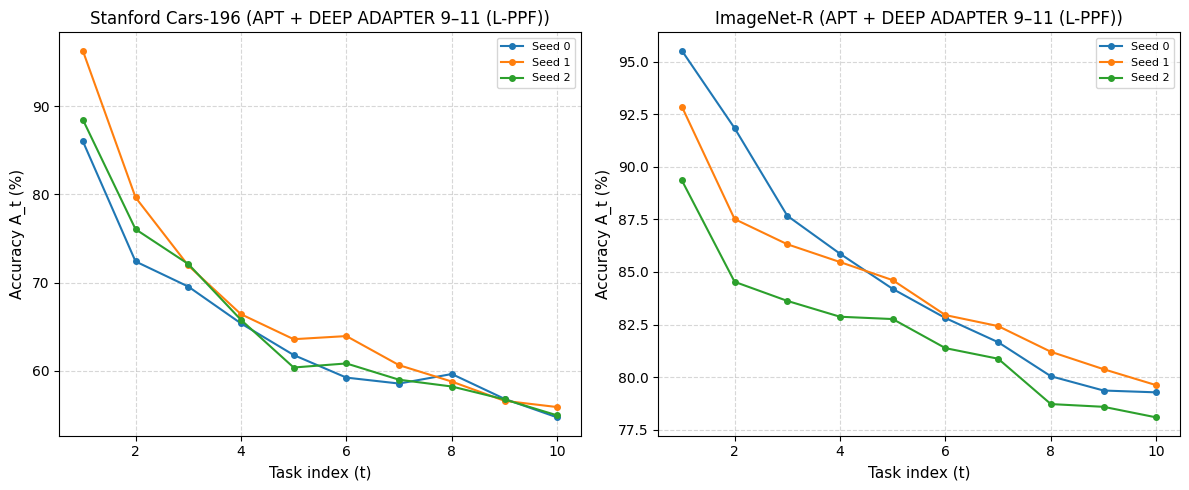

In [8]:
import matplotlib.pyplot as plt

master_rows = []

for ds_key, ds_results in ALL_RESULTS.items():
    ds_name = DATASET_CONFIGS[ds_key]["name"]
    for k, r in ds_results.items():
        comp = r.get("complexity", {})
        master_rows.append({
            "Dataset": ds_name,
            "Experiment": k,
            "Trainable (M)": round(comp.get("n_trainable", 0) / 1e6, 3),
            "GFLOPs": comp.get("gflops", 16.896),
            "Phase": r.get("phase", "val").upper(),
            "Seed": r.get("seed", 0),
            "Last Acc (%)": round(r.get("last", 0.0), 2),
            "Avg Acc (%)": round(r.get("avg", 0.0), 2),
            "Forgetting (%)": round(r.get("forgetting", 0.0), 2)
        })

df_all = pd.DataFrame(master_rows)
if not df_all.empty:
    print("📋 BẢNG KẾT QUẢ CHI TIẾT TỪNG SEED (KÈM PARAMS & FLOPS):", flush=True)
    display(df_all)
    df_all.to_csv(os.path.join(GLOBAL_CFG["base_out_dir"], "master_deep9_11_lppf_detailed.csv"), index=False)

    print("\n🏆 BẢNG MASTER: SO SÁNH HIỆU NĂNG APT + DEEP ADAPTER 9–11 (L-PPF) QUA CÁC DATASET (MEAN ± STD):", flush=True)
    master_stats = df_all.groupby(["Dataset", "Phase"]).agg({
        "Trainable (M)": "first",
        "GFLOPs": "first",
        "Last Acc (%)": ["mean", "std"],
        "Avg Acc (%)": ["mean", "std"],
        "Forgetting (%)": ["mean", "std"]
    }).round(2)
    display(master_stats)
    master_stats.to_csv(os.path.join(GLOBAL_CFG["base_out_dir"], "master_deep9_11_lppf_mean_std.csv"))

    # Vẽ biểu đồ so sánh đường cong A_t giữa các dataset
    n_datasets = len(ALL_RESULTS)
    fig, axes = plt.subplots(1, n_datasets, figsize=(6 * n_datasets, 5), squeeze=False)
    
    for i, (ds_key, ds_results) in enumerate(ALL_RESULTS.items()):
        ax = axes[0, i]
        ds_name = DATASET_CONFIGS[ds_key]["name"]
        for k, r in ds_results.items():
            a_t = r.get("A_t", [])
            if a_t:
                ax.plot(range(1, len(a_t) + 1), a_t, marker="o", markersize=4, label=f"Seed {r.get('seed')}")
        ax.set_xlabel("Task index (t)", fontsize=11)
        ax.set_ylabel("Accuracy A_t (%)", fontsize=11)
        ax.set_title(f"{ds_name} (APT + DEEP ADAPTER 9–11 (L-PPF))", fontsize=12)
        ax.grid(True, linestyle="--", alpha=0.5)
        ax.legend(loc="best", fontsize=8)

    plt.tight_layout()
    plt.savefig(os.path.join(GLOBAL_CFG["base_out_dir"], "master_deep9_11_lppf_curves.png"), dpi=150)
    plt.show()
